In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
!pip -q install transformers==4.57.1 datasets accelerate sentencepiece sacremoses scikit-learn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [8]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/NLP_HW2')

for folder in ['data', 'results', 'models', 'logs']:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/NLP_HW2


In [4]:
import pandas as pd

BASE_URL = "https://raw.githubusercontent.com/e9t/nsmc/master/"

train_df = pd.read_csv(
    BASE_URL + "ratings_train.txt",
    sep="\t"
)

test_df = pd.read_csv(
    BASE_URL + "ratings_test.txt",
    sep="\t"
)

print("Original training size:", len(train_df))
print("Original test size:", len(test_df))

train_df.head()

Original training size: 150000
Original test size: 50000


,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


In [5]:
import transformers
import datasets
import accelerate
import sklearn
import sentencepiece
import sacremoses

from transformers import MarianMTModel, MarianTokenizer
from transformers import Trainer, TrainingArguments

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nAll required libraries imported successfully!")

Transformers: 4.57.1
Datasets: 4.8.5
Accelerate: 1.15.0
Scikit-learn: 1.6.1

All required libraries imported successfully!


In [6]:
def clean_dataset(df):
    df = df.dropna(subset=["document"]).copy()

    df["document"] = df["document"].astype(str).str.strip()

    df = df[df["document"] != ""]
    df = df.drop_duplicates(subset=["id"])

    return df.reset_index(drop=True)


train_clean = clean_dataset(train_df)
test_clean = clean_dataset(test_df)

# Ensure no overlapping review IDs
assert set(train_clean["id"]).isdisjoint(test_clean["id"])

print("Training before cleaning:", len(train_df))
print("Training after cleaning:", len(train_clean))

print("Testing before cleaning:", len(test_df))
print("Testing after cleaning:", len(test_clean))

print("\nTraining label distribution:")
print(train_clean["label"].value_counts())

print("\nTesting label distribution:")
print(test_clean["label"].value_counts())

Training before cleaning: 150000
Training after cleaning: 149995
Testing before cleaning: 50000
Testing after cleaning: 49997

Training label distribution:
label
0    75170
1    74825
Name: count, dtype: int64

Testing label distribution:
label
1    25171
0    24826
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

DATA_SEED = 42

def balanced_sample(df, n_per_class, seed):
    negative = df[df["label"] == 0].sample(
        n=n_per_class,
        random_state=seed
    )

    positive = df[df["label"] == 1].sample(
        n=n_per_class,
        random_state=seed
    )

    return pd.concat([negative, positive]).sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)


# Select 10,000 training/validation reviews
train_subset = balanced_sample(
    train_clean, 5000, DATA_SEED
)

# Select 2,000 held-out test reviews
test_set = balanced_sample(
    test_clean, 1000, DATA_SEED
)

# Split training subset into 90% training and 10% validation
train_set, val_set = train_test_split(
    train_subset,
    test_size=0.1,
    random_state=DATA_SEED,
    stratify=train_subset["label"]
)

train_set = train_set.reset_index(drop=True)
val_set = val_set.reset_index(drop=True)

print("Training size:", len(train_set))
print("Validation size:", len(val_set))
print("Testing size:", len(test_set))

Training size: 9000
Validation size: 1000
Testing size: 2000


In [9]:
# Check that review IDs never overlap

train_ids = set(train_set["id"])
val_ids = set(val_set["id"])
test_ids = set(test_set["id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("No overlapping review IDs detected!")

# Display class distribution
summary = pd.DataFrame({
    "Training": train_set["label"].value_counts(),
    "Validation": val_set["label"].value_counts(),
    "Testing": test_set["label"].value_counts()
})

summary.index = summary.index.map({
    0: "Negative",
    1: "Positive"
})

display(summary)

# Save each split
train_set.to_csv(
    PROJECT_DIR / "data/train_ko.csv", index=False
)

val_set.to_csv(
    PROJECT_DIR / "data/val_ko.csv", index=False
)

test_set.to_csv(
    PROJECT_DIR / "data/test_ko.csv", index=False
)

print("All dataset splits saved successfully!")


No overlapping review IDs detected!


,Training,Validation,Testing
label,,,
Positive,4500,500,1000
Negative,4500,500,1000


All dataset splits saved successfully!


In [10]:
import torch
from transformers import MarianMTModel, MarianTokenizer

MT_MODEL = "Helsinki-NLP/opus-mt-ko-en"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

mt_tokenizer = MarianTokenizer.from_pretrained(MT_MODEL)

mt_model = MarianMTModel.from_pretrained(MT_MODEL)
mt_model = mt_model.to(device)
mt_model.eval()

print("Translation model:", MT_MODEL)
print("Device:", device)
print("Translation model loaded successfully!")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/842k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/813k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/312M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/312M [00:00<?, ?B/s]

Translation model: Helsinki-NLP/opus-mt-ko-en
Device: cuda
Translation model loaded successfully!


In [11]:
def translate_batch(texts):
    inputs = mt_tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=256
    ).to(device)

    with torch.inference_mode():
        outputs = mt_model.generate(
            **inputs,
            max_new_tokens=256,
            num_beams=4,
            do_sample=False
        )

    return mt_tokenizer.batch_decode(
        outputs,
        skip_special_tokens=True
    )


# Pilot using training data only
pilot = train_set.sample(
    n=10,
    random_state=42
).copy()

pilot["translation"] = translate_batch(
    pilot["document"].tolist()
)

for _, row in pilot.iterrows():
    print("Korean:", row["document"])
    print("English:", row["translation"])
    print("Label:", "Positive" if row["label"] == 1 else "Negative")
    print("-" * 60)

pilot.to_csv(
    PROJECT_DIR / "data/translation_pilot.csv",
    index=False
)


Korean: 나도 욕나오는...
English: I don't know what to say.
Label: Negative
------------------------------------------------------------
Korean: 진정한 작품성을 느낀영화.. 이만희 감독 최고!
English: I'm sorry, I'm sorry. I'm sorry.
Label: Positive
------------------------------------------------------------
Korean: 나만 죽을수 없다...완전 재밌음...손발이 오글오글...
English: I can't be the only one who's gonna die.
Label: Positive
------------------------------------------------------------
Korean: 왜!!!
English: Why?!
Label: Negative
------------------------------------------------------------
Korean: 웰메이드 영화. 흥행 놓친 거 안타깝지만 배우들 열연과 연출이 최고인 듯.
English: I'm sorry you missed the show, but the actors are the best in the show and show.
Label: Positive
------------------------------------------------------------
Korean: 전 오랜만에 몰입하면서 본 좋은 영화였습니다
English: It's been a long time since I've seen a great movie.
Label: Positive
------------------------------------------------------------
Korean: 성관계와 유산에 대한 저급한 인식. 도대체 고등학교 1학년이 성관계를 가지는건 뭐

In [12]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

model = AutoModelForSequenceClassification.from_pretrained(
    "xlm-roberta-base",
    num_labels=2
)

inputs = tokenizer(
    "정말 재미있는 영화였습니다!",
    return_tensors="pt"
)

model.eval()

with torch.no_grad():
    output = model(**inputs)

print("Output shape:", output.logits.shape)
print("Smoke test passed!")

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Output shape: torch.Size([1, 2])
Smoke test passed!


In [ ]:
import time
from tqdm.auto import tqdm

BATCH_SIZE = 16

pilot_large = train_set[
    ~train_set["id"].isin(pilot["id"])
].sample(
    n=100,
    random_state=42
).copy()

translations = []

start_time = time.time()

for i in tqdm(range(0, len(pilot_large), BATCH_SIZE)):
    batch = pilot_large["document"].iloc[
        i:i + BATCH_SIZE
    ].tolist()

    translations.extend(translate_batch(batch))

pilot_large["translation"] = translations

elapsed = time.time() - start_time

pilot_large.to_csv(
    PROJECT_DIR / "data/translation_pilot_100.csv",
    index=False
)

print(f"Translated: {len(pilot_large)} reviews")
print(f"Time taken: {elapsed:.2f} seconds")
print(f"Estimated full translation: {elapsed * 120 / 3600:.2f} hours")

print("Empty translations:",
      pilot_large["translation"].str.strip().eq("").sum())

display(pilot_large.head(10))


  0%|          | 0/7 [00:00<?, ?it/s]

Translated: 100 reviews
Time taken: 5.50 seconds
Estimated full translation: 0.18 hours
Empty translations: 0


,id,document,label,translation
1154,1375333,오래전에 봤었는데 다시 보고 싶어지네요 ^^,1,"I've seen it a long time ago, and I want to se..."
8667,9321439,아..제임스맥어보이 타고난배우,1,"Oh, James McBoy, a natural actor."
5217,10145614,말이 필요 없는 영화 최고 입니다,1,It's the best movie I've ever seen.
7714,6131163,유다인씨 참 예쁘고 연기도 잘하네요,1,You're so pretty and you're so good at acting.
4542,9048450,어설픈 전개 어이없는 결말,0,Fabulous development. This is a crazy ending.
2375,1825368,요즘초딩들은 이재미를 모르겠찌 ㅋㅋㅋㅋㅋㅋ,1,I don't think that's the fun you're having the...
1490,6672163,웃기고 웃기고 웃김 ㅋㅋ나름 반전도 있어서 좋았음 ㅋㅋㅋㅋ,1,"It's funny, it's funny, it's funny."
5062,8657009,신하균 덕에 재밌게 볼 수 있었던 영화,1,A film that I enjoyed because of the H.I.V.
6527,9785976,질질안끌기는..ㅋㅋ지금 장미빛 연인들 시청자의견게시판 가봐요 너무 질질끌어서 답답하...,0,I've never seen a show like this before becaus...
4179,9301165,남자인 내가 이 남자의 마음을 알 수있을까...또한 그러한 사랑을 할 수 있을까.....,1,"I wonder if I, as a man, can know the heart of..."


In [ ]:
import os

def translate_dataset(df, split_name, batch_size=16):

    output_path = (
        PROJECT_DIR / f"data/{split_name}_translated.csv"
    )

    df = df.copy().reset_index(drop=True)

    # Resume from existing progress
    if output_path.exists():

        saved = pd.read_csv(
            output_path,
            keep_default_na=False
        )

        assert saved["id"].tolist() == df["id"].iloc[
            :len(saved)
        ].tolist(), "Checkpoint IDs do not match!"

        assert saved["label"].tolist() == df["label"].iloc[
            :len(saved)
        ].tolist(), "Checkpoint labels do not match!"

        records = saved.to_dict("records")

        print(
            f"Resuming {split_name}: "
            f"{len(records)}/{len(df)} completed"
        )

    else:
        records = []
        print(f"Starting {split_name} translation")

    start_index = len(records)

    for i in tqdm(
        range(start_index, len(df), batch_size),
        desc=f"Translating {split_name}"
    ):

        batch = df.iloc[i:i + batch_size].copy()

        translated = translate_batch(
            batch["document"].tolist()
        )

        assert len(translated) == len(batch)

        batch["translation"] = translated

        records.extend(batch.to_dict("records"))

        # Save every 10 batches or at completion
        batch_number = (i - start_index) // batch_size + 1

        if batch_number % 10 == 0 or len(records) == len(df):

            temp_path = output_path.with_suffix(".tmp")

            pd.DataFrame(records).to_csv(
                temp_path,
                index=False
            )

            os.replace(temp_path, output_path)

    result = pd.DataFrame(records)

    assert len(result) == len(df)
    assert result["id"].tolist() == df["id"].tolist()
    assert result["label"].tolist() == df["label"].tolist()

    print(f"\n{split_name} translation complete!")
    print(f"Saved to: {output_path}")
    print(f"Total reviews: {len(result)}")

    return result


In [ ]:
val_translated = translate_dataset(
    val_set,
    split_name="val",
    batch_size=BATCH_SIZE
)

display(val_translated.head())


Starting val translation


Translating val:   0%|          | 0/63 [00:00<?, ?it/s]


val translation complete!
Saved to: /content/drive/MyDrive/NLP_HW2/data/val_translated.csv
Total reviews: 1000


,id,document,label,translation
0,10249491,쥬라기 공원은 다 재밌다,1,Jurassic Park is fun.
1,8196169,왜 이영화를싫어하지??아주재미있고 좋은데,1,Why don't you like this movie?
2,9970257,여러가지를 생각하게 하는 영화였습니다^^,1,It was a film that made me think about things.
3,9806329,영화 내용이야 영화 보기 전에 알고 있었고... 그래도 넓은 화면으로 사진을 보고 ...,1,"I knew it before I saw it, but I'm happy to se..."
4,4421800,1빠,1,Two.


In [ ]:
train_translated = translate_dataset(
    train_set,
    split_name="train",
    batch_size=BATCH_SIZE
)

display(train_translated.head())


Starting train translation


Translating train:   0%|          | 0/563 [00:00<?, ?it/s]


train translation complete!
Saved to: /content/drive/MyDrive/NLP_HW2/data/train_translated.csv
Total reviews: 9000


,id,document,label,translation
0,10240816,영화 보는 내내 뭔가 모를 편안함을 느꼈어요,1,"The whole time I was watching the movie, I fel..."
1,1791971,대런 아로노프스키의 비범함,1,Daron Aronovski's extraordinaryness.
2,9126569,감독 애미 없냐 ㅡㅡ 남성인권 개 졷으로 보는 영화 개 노잼이다 보지마라 진심,0,Don't look at me. Don't look at me.
3,8511430,겨울왕국의 거품인기를 보다 문득 이 작품이 생각나 들어와 평점을 남긴다.,1,The winter kingdom's popularity of bubble come...
4,8221302,너무 사소한 일가지고 목숨걸고 싸우네; ㅋㅋ 이상한 스토리야,0,It's a weird story.


In [ ]:
test_translated = translate_dataset(
    test_set,
    split_name="test",
    batch_size=BATCH_SIZE
)

display(test_translated.head())


Starting test translation


Translating test:   0%|          | 0/125 [00:00<?, ?it/s]


test translation complete!
Saved to: /content/drive/MyDrive/NLP_HW2/data/test_translated.csv
Total reviews: 2000


,id,document,label,translation
0,9257248,생각보다 단순했지만 나름 흥미진진했어요,1,"It was simpler than I thought, but it was exci..."
1,6137436,그냥 시간때우기용.,0,Just do it on time.
2,9689194,이런 영화 너무 좋음...,1,I love this movie so much...
3,7928591,"일단 엠씨 역량 부족이 가장 큰 문제인듯. 시간 없다고, 재미없다고 게스트 말 끊는...",0,"I mean, I've seen you quit saying you don't ha..."
4,9740867,"""""""난 널 사랑해...""""""",1,"""I love you..."""


In [ ]:
summary = []

for name, original, translated in [
    ("Training", train_set, train_translated),
    ("Validation", val_set, val_translated),
    ("Testing", test_set, test_translated)
]:

    assert len(original) == len(translated)

    assert original["id"].tolist() == translated["id"].tolist()

    assert original["label"].tolist() == translated["label"].tolist()

    empty_count = translated["translation"].fillna("").str.strip().eq("").sum()

    summary.append({
        "Dataset": name,
        "Original reviews": len(original),
        "Translated reviews": len(translated),
        "Empty translations": empty_count
    })

translation_summary = pd.DataFrame(summary)

display(translation_summary)

translation_summary.to_csv(
    PROJECT_DIR / "results/translation_summary.csv",
    index=False
)

print("All dataset IDs and labels match!")


,Dataset,Original reviews,Translated reviews,Empty translations
0,Training,9000,9000,0
1,Validation,1000,1000,0
2,Testing,2000,2000,0


All dataset IDs and labels match!


In [ ]:
for split, total in [
    ("train", 9000),
    ("val", 1000),
    ("test", 2000)
]:
    path = PROJECT_DIR / f"data/{split}_translated.csv"

    if path.exists():
        count = len(pd.read_csv(path))
        print(f"{split}: {count}/{total} ({count/total:.1%})")
    else:
        print(f"{split}: Not started")


train: 9000/9000 (100.0%)
val: 1000/1000 (100.0%)
test: 2000/2000 (100.0%)


In [ ]:
import shutil
import torch

total, used, free = shutil.disk_usage("/content")

print(f"Colab disk available: {free / 1024**3:.2f} GB")

if torch.cuda.is_available():
    free_gpu, total_gpu = torch.cuda.mem_get_info()
    print(f"GPU memory available: {free_gpu / 1024**3:.2f} GB")
    print(f"Total GPU memory: {total_gpu / 1024**3:.2f} GB")


In [ ]:
import pandas as pd
import os
from tqdm.auto import tqdm

# Reload original datasets from Google Drive
train_set = pd.read_csv(
    PROJECT_DIR / "data/train_ko.csv",
    keep_default_na=False,
    dtype={"document": str}
)

val_set = pd.read_csv(
    PROJECT_DIR / "data/val_ko.csv",
    keep_default_na=False,
    dtype={"document": str}
)

test_set = pd.read_csv(
    PROJECT_DIR / "data/test_ko.csv",
    keep_default_na=False,
    dtype={"document": str}
)

print("Training:", len(train_set))
print("Validation:", len(val_set))
print("Testing:", len(test_set))

BATCH_SIZE = 16


Training: 9000
Validation: 1000
Testing: 2000


In [ ]:
def translate_batch(texts):
    inputs = mt_tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=256
    ).to(device)

    with torch.inference_mode():
        outputs = mt_model.generate(
            **inputs,
            max_new_tokens=256,
            num_beams=4,
            do_sample=False
        )

    return mt_tokenizer.batch_decode(
        outputs,
        skip_special_tokens=True
    )

print("Translation function restored!")


Translation function restored!


In [ ]:
for split, total in [
    ("train", 9000),
    ("val", 1000),
    ("test", 2000)
]:
    path = PROJECT_DIR / f"data/{split}_translated.csv"

    if path.exists():
        count = len(pd.read_csv(path))

        print(
            f"{split}: {count}/{total} "
            f"({count/total:.1%})"
        )
    else:
        print(f"{split}: Not started")


train: 9000/9000 (100.0%)
val: 1000/1000 (100.0%)
test: 2000/2000 (100.0%)


In [ ]:
# Resume validation translation
val_translated = translate_dataset(
    val_set,
    split_name="val",
    batch_size=BATCH_SIZE
)

# Resume training translation
train_translated = translate_dataset(
    train_set,
    split_name="train",
    batch_size=BATCH_SIZE
)

# Resume test translation
test_translated = translate_dataset(
    test_set,
    split_name="test",
    batch_size=BATCH_SIZE
)

print("All translations completed!")


Resuming val: 1000/1000 completed


Translating val: 0it [00:00, ?it/s]


val translation complete!
Saved to: /content/drive/MyDrive/NLP_HW2/data/val_translated.csv
Total reviews: 1000
Resuming train: 9000/9000 completed


Translating train: 0it [00:00, ?it/s]


train translation complete!
Saved to: /content/drive/MyDrive/NLP_HW2/data/train_translated.csv
Total reviews: 9000
Resuming test: 2000/2000 completed


Translating test: 0it [00:00, ?it/s]


test translation complete!
Saved to: /content/drive/MyDrive/NLP_HW2/data/test_translated.csv
Total reviews: 2000
All translations completed!


In [ ]:
import gc
import torch
import pandas as pd

# Release translation model
if "mt_model" in globals():
    del mt_model

if "mt_tokenizer" in globals():
    del mt_tokenizer

gc.collect()
torch.cuda.empty_cache()

assert torch.cuda.is_available(), "Please enable GPU!"

# Load and verify datasets
splits = {}
summary = []

for name, expected in [
    ("train", 9000),
    ("val", 1000),
    ("test", 2000)
]:
    original = pd.read_csv(
        PROJECT_DIR / f"data/{name}_ko.csv",
        keep_default_na=False,
        dtype={"document": str}
    )

    translated = pd.read_csv(
        PROJECT_DIR / f"data/{name}_translated.csv",
        keep_default_na=False,
        dtype={"document": str, "translation": str}
    )

    assert len(original) == len(translated) == expected
    assert original["id"].tolist() == translated["id"].tolist()
    assert original["label"].tolist() == translated["label"].tolist()
    assert original["document"].tolist() == translated["document"].tolist()

    splits[name] = translated

    empty = translated["translation"].str.strip().eq("").sum()

    summary.append({
        "Dataset": name,
        "Original reviews": len(original),
        "Translated reviews": len(translated),
        "Empty translations": empty
    })

translation_summary = pd.DataFrame(summary)

display(translation_summary)

translation_summary.to_csv(
    PROJECT_DIR / "results/translation_summary.csv",
    index=False
)

free_gpu, total_gpu = torch.cuda.mem_get_info()

print(f"Available GPU memory: {free_gpu / 1024**3:.2f} GB")
print("Dataset verification complete!")


,Dataset,Original reviews,Translated reviews,Empty translations
0,train,9000,9000,0
1,val,1000,1000,0
2,test,2000,2000,0


Available GPU memory: 14.46 GB
Dataset verification complete!


In [ ]:
import numpy as np
import json
import transformers
import datasets
import accelerate
import sklearn

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

MODEL_NAME = "xlm-roberta-base"

MAX_LENGTH = 128
LEARNING_RATE = 2e-5
EPOCHS = 3
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
SEED = 42

print("Model:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Training batch size:", TRAIN_BATCH_SIZE)
print("Seed:", SEED)

print("\nTraining configuration ready!")


Model: xlm-roberta-base
Maximum sequence length: 128
Learning rate: 2e-05
Epochs: 3
Training batch size: 16
Seed: 42

Training configuration ready!


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

def prepare_dataset(df, text_column):

    model_df = df[[text_column, "label"]].copy()

    model_df = model_df.rename(
        columns={text_column: "text"}
    )

    dataset = Dataset.from_pandas(
        model_df,
        preserve_index=False
    )

    def tokenize(batch):
        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH
        )

    dataset = dataset.map(
        tokenize,
        batched=True,
        remove_columns=["text"]
    )

    return dataset


# Korean pipeline
ko_train = prepare_dataset(splits["train"], "document")
ko_val = prepare_dataset(splits["val"], "document")
ko_test = prepare_dataset(splits["test"], "document")

# Translated-English pipeline
en_train = prepare_dataset(splits["train"], "translation")
en_val = prepare_dataset(splits["val"], "translation")
en_test = prepare_dataset(splits["test"], "translation")

print("\nBoth pipelines are ready!")

print("Korean training:", len(ko_train))
print("Korean validation:", len(ko_val))
print("Korean testing:", len(ko_test))

print("English training:", len(en_train))
print("English validation:", len(en_val))
print("English testing:", len(en_test))


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/9000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/9000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]


Both pipelines are ready!
Korean training: 9000
Korean validation: 1000
Korean testing: 2000
English training: 9000
English validation: 1000
English testing: 2000


In [ ]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    return {
        "accuracy": accuracy_score(
            labels, predictions
        ),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

print("Evaluation metrics defined!")


Evaluation metrics defined!


In [ ]:
import shutil
from pathlib import Path

def train_classifier(
    condition,
    train_data,
    val_data,
    test_data,
    seed=42
):

    set_seed(seed)

    run_name = f"{condition}_seed{seed}"

    output_dir = Path(
        f"/content/checkpoints/{run_name}"
    )

    # Delete old temporary checkpoints
    if output_dir.exists():
        shutil.rmtree(output_dir)

    # Initialize model
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0: "Negative", 1: "Positive"},
        label2id={"Negative": 0, "Positive": 1}
    )

    # Training configuration
    training_args = TrainingArguments(
        output_dir=str(output_dir),

        learning_rate=LEARNING_RATE,

        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,

        num_train_epochs=EPOCHS,

        weight_decay=0.01,
        optim="adamw_torch",

        eval_strategy="epoch",
        save_strategy="epoch",

        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,

        save_total_limit=1,

        logging_steps=50,

        fp16=True,

        seed=seed,
        data_seed=seed,

        report_to="none"
    )

    # Create trainer
    trainer = Trainer(
        model=model,
        args=training_args,

        train_dataset=train_data,
        eval_dataset=val_data,

        processing_class=tokenizer,
        data_collator=data_collator,

        compute_metrics=compute_metrics
    )

    print(f"\nStarting experiment: {run_name}")

    # Train classifier
    trainer.train()

    # Evaluate best validation checkpoint
    test_output = trainer.predict(test_data)

    predictions = np.argmax(
        test_output.predictions,
        axis=-1
    )

    labels = test_output.label_ids

    results = {
        "condition": condition,
        "seed": seed,
        "accuracy": float(
            accuracy_score(labels, predictions)
        ),
        "macro_f1": float(
            f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            )
        ),
        "test_size": len(labels)
    }

    # Save individual predictions
    prediction_df = splits["test"][
        ["id", "document", "translation", "label"]
    ].copy()

    assert np.array_equal(
        labels,
        prediction_df["label"].to_numpy()
    )

    prediction_df["prediction"] = predictions

    prediction_df["correct"] = (
        prediction_df["label"] ==
        prediction_df["prediction"]
    )

    prediction_df.to_csv(
        PROJECT_DIR / f"results/{run_name}_predictions.csv",
        index=False
    )

    # Save metrics
    with open(
        PROJECT_DIR / f"results/{run_name}_metrics.json",
        "w"
    ) as f:
        json.dump(results, f, indent=4)

    # Save training history
    pd.DataFrame(
        trainer.state.log_history
    ).to_csv(
        PROJECT_DIR / f"logs/{run_name}_training.csv",
        index=False
    )

    # Save configuration for reproducibility
    config = {
        "model": MODEL_NAME,
        "model_revision": getattr(
            model.config, "_commit_hash", None
        ),
        "max_length": MAX_LENGTH,
        "best_checkpoint": trainer.state.best_model_checkpoint,
        "training_arguments": training_args.to_dict(),
        "torch_version": torch.__version__,
        "transformers_version": transformers.__version__,
        "datasets_version": datasets.__version__,
        "accelerate_version": accelerate.__version__,
        "sklearn_version": sklearn.__version__,
        "gpu": torch.cuda.get_device_name(0)
    }

    with open(
        PROJECT_DIR / f"logs/{run_name}_config.json",
        "w"
    ) as f:
        json.dump(config, f, indent=4, default=str)

    print("\nFinal test results:")
    print(json.dumps(results, indent=4))

    print("\nClassification report:")
    print(classification_report(
        labels,
        predictions,
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

    print("\nConfusion matrix:")
    print(confusion_matrix(labels, predictions))

    # Release GPU memory
    del trainer
    del model
    del test_output

    gc.collect()
    torch.cuda.empty_cache()

    # Remove temporary checkpoints
    shutil.rmtree(output_dir, ignore_errors=True)

    print("\nResults saved to Google Drive!")

    return results


print("Training function ready!")


Training function ready!


In [ ]:
ko_results = train_classifier(
    condition="KO",
    train_data=ko_train,
    val_data=ko_val,
    test_data=ko_test,
    seed=42
)


model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Starting experiment: KO_seed42


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.435100,0.427367,0.818000,0.816514
2,0.382900,0.354865,0.869000,0.868942
3,0.290100,0.363246,0.865000,0.864886



Final test results:
{
    "condition": "KO",
    "seed": 42,
    "accuracy": 0.8435,
    "macro_f1": 0.8433900206419959,
    "test_size": 2000
}

Classification report:
              precision    recall  f1-score   support

    Negative       0.86      0.82      0.84      1000
    Positive       0.83      0.87      0.85      1000

    accuracy                           0.84      2000
   macro avg       0.84      0.84      0.84      2000
weighted avg       0.84      0.84      0.84      2000


Confusion matrix:
[[817 183]
 [130 870]]

Results saved to Google Drive!


In [ ]:
en_results = train_classifier(
    condition="KO_EN",
    train_data=en_train,
    val_data=en_val,
    test_data=en_test,
    seed=42
)


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Starting experiment: KO_EN_seed42


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.488800,0.507059,0.755000,0.754085
2,0.492000,0.473423,0.777000,0.776936
3,0.345000,0.513705,0.781000,0.780998



Final test results:
{
    "condition": "KO_EN",
    "seed": 42,
    "accuracy": 0.7835,
    "macro_f1": 0.7834986468665429,
    "test_size": 2000
}

Classification report:
              precision    recall  f1-score   support

    Negative       0.78      0.79      0.78      1000
    Positive       0.78      0.78      0.78      1000

    accuracy                           0.78      2000
   macro avg       0.78      0.78      0.78      2000
weighted avg       0.78      0.78      0.78      2000


Confusion matrix:
[[786 214]
 [219 781]]

Results saved to Google Drive!


In [ ]:
# Reload saved results from Google Drive
# This also works after a runtime reset

with open(PROJECT_DIR / "results/KO_seed42_metrics.json") as f:
    ko_results = json.load(f)

with open(PROJECT_DIR / "results/KO_EN_seed42_metrics.json") as f:
    en_results = json.load(f)

results_df = pd.DataFrame([
    ko_results,
    en_results
])

display(results_df)

results_df.to_csv(
    PROJECT_DIR / "results/main_results_seed42.csv",
    index=False
)

accuracy_diff = (
    ko_results["accuracy"] -
    en_results["accuracy"]
)

f1_diff = (
    ko_results["macro_f1"] -
    en_results["macro_f1"]
)

print(
    f"Accuracy difference (KO - KO_EN): "
    f"{accuracy_diff * 100:.2f} percentage points"
)

print(
    f"Macro-F1 difference (KO - KO_EN): "
    f"{f1_diff * 100:.2f} percentage points"
)


,condition,seed,accuracy,macro_f1,test_size
0,KO,42,0.8435,0.843390,2000
1,KO_EN,42,0.7835,0.783499,2000


Accuracy difference (KO - KO_EN): 6.00 percentage points
Macro-F1 difference (KO - KO_EN): 5.99 percentage points


In [ ]:
for seed in [43, 44]:

    print(f"\n===== RANDOM SEED {seed} =====")

    train_classifier(
        condition="KO",
        train_data=ko_train,
        val_data=ko_val,
        test_data=ko_test,
        seed=seed
    )

    train_classifier(
        condition="KO_EN",
        train_data=en_train,
        val_data=en_val,
        test_data=en_test,
        seed=seed
    )

print("All three random seeds completed!")



===== RANDOM SEED 43 =====


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Starting experiment: KO_seed43


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.432300,0.361887,0.842000,0.841503
2,0.298500,0.343694,0.861000,0.860547
3,0.220700,0.367134,0.873000,0.872954



Final test results:
{
    "condition": "KO",
    "seed": 43,
    "accuracy": 0.8465,
    "macro_f1": 0.846407806285723,
    "test_size": 2000
}

Classification report:
              precision    recall  f1-score   support

    Negative       0.86      0.82      0.84      1000
    Positive       0.83      0.87      0.85      1000

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000


Confusion matrix:
[[822 178]
 [129 871]]

Results saved to Google Drive!


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (7 outputs left out)

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Starting experiment: KO_EN_seed44


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.523500,0.498419,0.760000,0.759812
2,0.402900,0.509203,0.788000,0.787979
3,0.345900,0.534572,0.786000,0.785997



Final test results:
{
    "condition": "KO_EN",
    "seed": 44,
    "accuracy": 0.776,
    "macro_f1": 0.775942641316177,
    "test_size": 2000
}

Classification report:
              precision    recall  f1-score   support

    Negative       0.79      0.76      0.77      1000
    Positive       0.77      0.79      0.78      1000

    accuracy                           0.78      2000
   macro avg       0.78      0.78      0.78      2000
weighted avg       0.78      0.78      0.78      2000


Confusion matrix:
[[760 240]
 [208 792]]

Results saved to Google Drive!
All three random seeds completed!


In [ ]:
all_results = []

for seed in [42, 43, 44]:
    for condition in ["KO", "KO_EN"]:

        path = (
            PROJECT_DIR /
            f"results/{condition}_seed{seed}_metrics.json"
        )

        with open(path) as f:
            all_results.append(json.load(f))

all_results_df = pd.DataFrame(all_results)

print("Individual experimental results:")
display(all_results_df)

# Mean and standard deviation
final_summary = all_results_df.groupby("condition").agg(
    accuracy_mean=("accuracy", "mean"),
    accuracy_std=("accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_std=("macro_f1", "std")
) * 100

print("\nFinal results across three seeds:")
display(final_summary.round(3))

all_results_df.to_csv(
    PROJECT_DIR / "results/all_seed_results.csv",
    index=False
)

final_summary.to_csv(
    PROJECT_DIR / "results/final_main_results.csv"
)

print("Final experimental results saved!")


Individual experimental results:


,condition,seed,accuracy,macro_f1,test_size
0,KO,42,0.8435,0.843390,2000
1,KO_EN,42,0.7835,0.783499,2000
2,KO,43,0.8465,0.846408,2000
3,KO_EN,43,0.7815,0.781499,2000
4,KO,44,0.8440,0.843965,2000
5,KO_EN,44,0.7760,0.775943,2000



Final results across three seeds:


,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
condition,,,,
KO,84.467,0.161,84.459,0.160
KO_EN,78.033,0.388,78.031,0.391


Final experimental results saved!


In [ ]:
from scipy.stats import binomtest
import numpy as np
import pandas as pd

SEEDS = [42, 43, 44]
paired_results = {}

for seed in SEEDS:

    ko = pd.read_csv(
        PROJECT_DIR / f"results/KO_seed{seed}_predictions.csv",
        keep_default_na=False
    )

    en = pd.read_csv(
        PROJECT_DIR / f"results/KO_EN_seed{seed}_predictions.csv",
        keep_default_na=False
    )

    paired = ko.merge(
        en[["id", "label", "prediction"]],
        on="id",
        suffixes=("_ko", "_en"),
        validate="one_to_one"
    )

    assert len(paired) == 2000

    assert (
        paired["label_ko"] == paired["label_en"]
    ).all()

    paired["label"] = paired["label_ko"]

    paired["ko_correct"] = (
        paired["prediction_ko"] == paired["label"]
    )

    paired["en_correct"] = (
        paired["prediction_en"] == paired["label"]
    )

    paired = paired.sort_values("id").reset_index(drop=True)

    paired_results[seed] = paired

    paired.to_csv(
        PROJECT_DIR / f"results/paired_seed{seed}.csv",
        index=False
    )

    print(f"Seed {seed}: {len(paired)} matched reviews")

print("\nAll predictions successfully matched!")


Seed 42: 2000 matched reviews
Seed 43: 2000 matched reviews
Seed 44: 2000 matched reviews

All predictions successfully matched!


In [ ]:
mcnemar_results = []

for seed, paired in paired_results.items():

    ko_correct = paired["ko_correct"]
    en_correct = paired["en_correct"]

    a = int((ko_correct & en_correct).sum())
    b = int((ko_correct & ~en_correct).sum())
    c = int((~ko_correct & en_correct).sum())
    d = int((~ko_correct & ~en_correct).sum())

    # Exact two-sided McNemar test
    p_value = (
        binomtest(
            b,
            n=b+c,
            p=0.5,
            alternative="two-sided"
        ).pvalue
        if b+c > 0 else 1.0
    )

    mcnemar_results.append({
        "seed": seed,
        "both_correct": a,
        "only_ko_correct": b,
        "only_en_correct": c,
        "both_incorrect": d,
        "p_value": p_value
    })

mcnemar_df = pd.DataFrame(mcnemar_results)

# Bonferroni correction for three tests
mcnemar_df["adjusted_p_value"] = (
    mcnemar_df["p_value"] * len(SEEDS)
).clip(upper=1)

mcnemar_df["significant"] = (
    mcnemar_df["adjusted_p_value"] < 0.05
)

display(mcnemar_df)

mcnemar_df.to_csv(
    PROJECT_DIR / "results/mcnemar_results.csv",
    index=False
)

print("McNemar test results saved!")


,seed,both_correct,only_ko_correct,only_en_correct,both_incorrect,p_value,adjusted_p_value,significant
0,42,1445,242,122,191,3.101292e-10,9.303876e-10,True
1,43,1444,249,119,188,1.082272e-11,3.246815e-11,True
2,44,1432,256,120,192,1.936394e-12,5.809181e-12,True


McNemar test results saved!


In [ ]:
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

BOOTSTRAP_SEED = 2026
N_BOOTSTRAP = 5000

rng = np.random.default_rng(BOOTSTRAP_SEED)

reference = paired_results[42]

labels = reference["label"].to_numpy()
review_ids = reference["id"].to_numpy()

ko_predictions = []
en_predictions = []

for seed in SEEDS:

    paired = paired_results[seed]

    assert np.array_equal(
        paired["id"].to_numpy(), review_ids
    )

    assert np.array_equal(
        paired["label"].to_numpy(), labels
    )

    ko_predictions.append(
        paired["prediction_ko"].to_numpy()
    )

    en_predictions.append(
        paired["prediction_en"].to_numpy()
    )

ko_predictions = np.array(ko_predictions)
en_predictions = np.array(en_predictions)

accuracy_diffs = []
f1_diffs = []

n = len(labels)

for _ in tqdm(range(N_BOOTSTRAP)):

    indices = rng.integers(0, n, size=n)

    y = labels[indices]

    seed_accuracy_diffs = []
    seed_f1_diffs = []

    for i in range(len(SEEDS)):

        ko = ko_predictions[i, indices]
        en = en_predictions[i, indices]

        acc_diff = (
            (ko == y).mean() -
            (en == y).mean()
        )

        f1_diff = (
            f1_score(y, ko, average="macro",
                     zero_division=0) -
            f1_score(y, en, average="macro",
                     zero_division=0)
        )

        seed_accuracy_diffs.append(acc_diff)
        seed_f1_diffs.append(f1_diff)

    accuracy_diffs.append(
        np.mean(seed_accuracy_diffs)
    )

    f1_diffs.append(
        np.mean(seed_f1_diffs)
    )

accuracy_ci = np.percentile(
    accuracy_diffs, [2.5, 97.5]
) * 100

f1_ci = np.percentile(
    f1_diffs, [2.5, 97.5]
) * 100

bootstrap_df = pd.DataFrame([
    {
        "metric": "Accuracy",
        "observed_difference_pp": (
            final_summary.loc["KO", "accuracy_mean"] -
            final_summary.loc["KO_EN", "accuracy_mean"]
        ),
        "ci_lower_pp": accuracy_ci[0],
        "ci_upper_pp": accuracy_ci[1]
    },
    {
        "metric": "Macro-F1",
        "observed_difference_pp": (
            final_summary.loc["KO", "macro_f1_mean"] -
            final_summary.loc["KO_EN", "macro_f1_mean"]
        ),
        "ci_lower_pp": f1_ci[0],
        "ci_upper_pp": f1_ci[1]
    }
])

display(bootstrap_df.round(3))

bootstrap_df.to_csv(
    PROJECT_DIR / "results/bootstrap_results.csv",
    index=False
)

print("Bootstrap confidence intervals saved!")


  0%|          | 0/5000 [00:00<?, ?it/s]

,metric,observed_difference_pp,ci_lower_pp,ci_upper_pp
0,Accuracy,6.433,4.917,7.983
1,Macro-F1,6.427,4.911,7.979


Bootstrap confidence intervals saved!


In [ ]:
ANNOTATION_SEED = 2026
ANNOTATION_DIR = PROJECT_DIR / "annotation"

ANNOTATION_DIR.mkdir(exist_ok=True)

paired = paired_results[42].copy()

paired["outcome"] = np.select(
    [
        paired["ko_correct"] & paired["en_correct"],
        paired["ko_correct"] & ~paired["en_correct"],
        ~paired["ko_correct"] & paired["en_correct"]
    ],
    [
        "both_correct",
        "only_ko_correct",
        "only_en_correct"
    ],
    default="both_incorrect"
)

samples = []

for outcome, group in paired.groupby("outcome"):

    selected = group.sample(
        n=25,
        random_state=ANNOTATION_SEED
    ).copy()

    selected["sample_weight"] = len(group) / 25

    samples.append(selected)

annotation_sample = pd.concat(
    samples,
    ignore_index=True
)

annotation_sample = annotation_sample.sample(
    frac=1,
    random_state=ANNOTATION_SEED
).reset_index(drop=True)

annotation_sample["annotation_id"] = range(1, 101)

# Save private answer key for later analysis
annotation_sample.to_csv(
    ANNOTATION_DIR / "annotation_key.csv",
    index=False
)

# Prepare blind annotation file
annotation_sheet = annotation_sample[
    ["annotation_id", "document"]
].copy()

annotation_sheet = annotation_sheet.rename(
    columns={"document": "korean_review"}
)

for column in [
    "negation",
    "slang_idiom",
    "sarcasm_irony",
    "notes"
]:
    annotation_sheet[column] = ""

annotation_path = (
    ANNOTATION_DIR / "annotation_100.csv"
)

# Avoid overwriting an existing annotation file
if not annotation_path.exists():
    annotation_sheet.to_csv(
        annotation_path,
        index=False,
        encoding="utf-8-sig"
    )

print("Annotation sample:", len(annotation_sheet))

print("\nSampling distribution:")
print(annotation_sample["outcome"].value_counts())

print("\nAnnotation file saved!")
display(annotation_sheet.head())


Annotation sample: 100

Sampling distribution:
outcome
only_ko_correct    25
both_correct       25
only_en_correct    25
both_incorrect     25
Name: count, dtype: int64

Annotation file saved!


,annotation_id,korean_review,negation,slang_idiom,sarcasm_irony,notes
0,1,연기잘한느 배우들 나와서 보고있는데... 수애는 언제쯤 변할까요..? 답답하네요~ㅋㅋ,,,,
1,2,은근 슬프고 은근 감동 ㅠ.ㅠ,,,,
2,3,"모든 것이 느리다. 지리한 전개, 이어지는 황당 결말.",,,,
3,4,재미없다..,,,,
4,5,감동적이고 지루하지도 않고 기대 이상입니다. 다신 그의 연기를 볼 수 없다는게 더 ...,,,,


In [ ]:
ANNOTATION_DIR = PROJECT_DIR / "annotation"

annotations = pd.read_csv(
    ANNOTATION_DIR / "annotation_completed.csv",
    keep_default_na=False,
    dtype=str
)

features = [
    "negation",
    "slang_idiom",
    "sarcasm_irony"
]

annotations["annotation_id"] = (
    annotations["annotation_id"].astype(int)
)

assert len(annotations) == 100
assert annotations["annotation_id"].is_unique
assert set(annotations["annotation_id"]) == set(range(1, 101))

for feature in features:

    annotations[feature] = (
        annotations[feature].str.strip()
    )

    invalid = ~annotations[feature].isin(
        ["0", "1", "?"]
    )

    if invalid.any():
        print("Invalid annotations:", feature)
        display(annotations.loc[invalid])

    assert not invalid.any(), (
        f"Check annotation column: {feature}"
    )

print("All 100 annotations validated!")

for feature in features:
    print(f"\n{feature}:")
    print(annotations[feature].value_counts())



All 100 annotations validated!

negation:
negation
0    66
1    34
Name: count, dtype: int64

slang_idiom:
slang_idiom
1    74
0    26
Name: count, dtype: int64

sarcasm_irony:
sarcasm_irony
0    77
1    21
?     2
Name: count, dtype: int64


In [ ]:
annotation_key = pd.read_csv(
    ANNOTATION_DIR / "annotation_key.csv",
    keep_default_na=False
)

analyzed = annotation_key.merge(
    annotations[
        ["annotation_id"] + features + ["notes"]
    ],
    on="annotation_id",
    validate="one_to_one"
)

assert len(analyzed) == 100

analyzed["ko_correct"] = (
    analyzed["prediction_ko"] ==
    analyzed["label"]
)

analyzed["en_correct"] = (
    analyzed["prediction_en"] ==
    analyzed["label"]
)

# Identify reviews containing any target feature
analyzed["any_feature"] = np.where(
    analyzed[features].eq("1").any(axis=1),
    "1",
    np.where(
        analyzed[features].eq("?").any(axis=1),
        "?",
        "0"
    )
)

analyzed.to_csv(
    ANNOTATION_DIR / "annotation_analyzed.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Annotations and predictions successfully merged!")

display(analyzed.head())


Annotations and predictions successfully merged!


,id,document,translation,label_ko,prediction_ko,correct,label_en,prediction_en,label,ko_correct,en_correct,outcome,sample_weight,annotation_id,negation,slang_idiom,sarcasm_irony,notes,any_feature
0,9992614,연기잘한느 배우들 나와서 보고있는데... 수애는 언제쯤 변할까요..? 답답하네요~ㅋㅋ,"I'm looking out at the actors, and they're lik...",1,1,True,1,0,1,True,False,only_ko_correct,9.68,1,0,1,0,,1
1,4169185,은근 슬프고 은근 감동 ㅠ.ㅠ,"It’s sad, it’s moving.",1,1,True,1,1,1,True,True,both_correct,57.80,2,0,1,0,,1
2,3229898,"모든 것이 느리다. 지리한 전개, 이어지는 황당 결말.","It's all slow. It's boring, and it's going to ...",0,0,True,0,0,0,True,True,both_correct,57.80,3,0,0,0,,0
3,7003189,재미없다..,It's not funny.,0,0,True,0,0,0,True,True,both_correct,57.80,4,1,0,0,,1
4,9350461,감동적이고 지루하지도 않고 기대 이상입니다. 다신 그의 연기를 볼 수 없다는게 더 ...,"It's not moving, it's not boring, it's more th...",1,1,True,1,0,1,True,False,only_ko_correct,9.68,5,1,0,0,,1


In [ ]:
def weighted_accuracy(group, column):

    if len(group) == 0:
        return np.nan

    return np.average(
        group[column].astype(float),
        weights=group["sample_weight"]
    ) * 100


subgroup_results = []

for feature in features + ["any_feature"]:

    present = analyzed[analyzed[feature] == "1"]
    absent = analyzed[analyzed[feature] == "0"]

    ko_present = weighted_accuracy(
        present, "ko_correct"
    )

    en_present = weighted_accuracy(
        present, "en_correct"
    )

    ko_absent = weighted_accuracy(
        absent, "ko_correct"
    )

    en_absent = weighted_accuracy(
        absent, "en_correct"
    )

    present_gap = ko_present - en_present
    absent_gap = ko_absent - en_absent

    subgroup_results.append({
        "feature": feature,
        "present_n": len(present),
        "absent_n": len(absent),
        "uncertain_n": (
            analyzed[feature] == "?"
        ).sum(),
        "KO_present_acc": ko_present,
        "EN_present_acc": en_present,
        "present_gap_pp": present_gap,
        "KO_absent_acc": ko_absent,
        "EN_absent_acc": en_absent,
        "absent_gap_pp": absent_gap,
        "additional_gap_pp": (
            present_gap - absent_gap
        )
    })

subgroup_df = pd.DataFrame(subgroup_results)

display(subgroup_df.round(2))

subgroup_df.to_csv(
    PROJECT_DIR / "results/subgroup_results.csv",
    index=False
)

print("Linguistic subgroup analysis saved!")


,feature,present_n,absent_n,uncertain_n,KO_present_acc,EN_present_acc,present_gap_pp,KO_absent_acc,EN_absent_acc,absent_gap_pp,additional_gap_pp
0,negation,34,66,0,88.11,82.39,5.72,82.07,75.90,6.17,-0.45
1,slang_idiom,74,26,0,84.56,77.31,7.25,83.79,81.16,2.63,4.61
2,sarcasm_irony,21,77,2,77.14,75.83,1.30,86.20,79.72,6.48,-5.17
3,any_feature,80,20,0,84.99,78.69,6.30,81.78,76.99,4.79,1.51


Linguistic subgroup analysis saved!


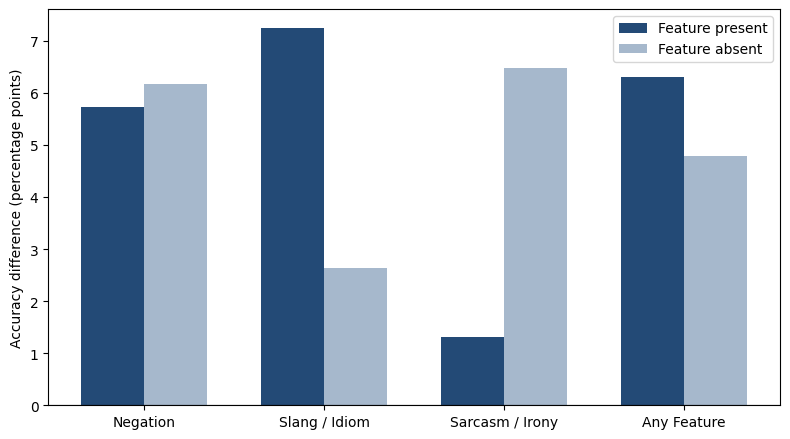

In [ ]:
import matplotlib.pyplot as plt

plot_df = subgroup_df.copy()

plot_df["feature"] = plot_df["feature"].map({
    "negation": "Negation",
    "slang_idiom": "Slang / Idiom",
    "sarcasm_irony": "Sarcasm / Irony",
    "any_feature": "Any Feature"
})

x = np.arange(len(plot_df))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(
    x - width/2,
    plot_df["present_gap_pp"],
    width,
    label="Feature present",
    color="#234A76"
)

ax.bar(
    x + width/2,
    plot_df["absent_gap_pp"],
    width,
    label="Feature absent",
    color="#A6B8CC"
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set_ylabel("Accuracy difference (percentage points)")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["feature"])
ax.legend()

plt.tight_layout()

FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

plt.savefig(
    FIGURE_DIR / "linguistic_subgroups.pdf",
    bbox_inches="tight"
)

plt.savefig(
    FIGURE_DIR / "linguistic_subgroups.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
example_groups = []

for outcome, group in analyzed.groupby("outcome"):

    examples = group.sample(
        n=min(5, len(group)),
        random_state=2026
    )

    example_groups.append(examples)

error_examples = pd.concat(
    example_groups,
    ignore_index=True
)

columns = [
    "annotation_id",
    "document",
    "translation",
    "label",
    "prediction_ko",
    "prediction_en",
    "outcome",
    "negation",
    "slang_idiom",
    "sarcasm_irony"
]

error_examples = error_examples[columns]

error_examples.to_csv(
    PROJECT_DIR / "results/qualitative_examples.csv",
    index=False,
    encoding="utf-8-sig"
)

for _, row in error_examples.iterrows():

    print("ID:", row["annotation_id"])
    print("Korean:", row["document"])
    print("English:", row["translation"])
    print("Gold label:", row["label"])
    print("KO prediction:", row["prediction_ko"])
    print("EN prediction:", row["prediction_en"])
    print("Outcome:", row["outcome"])
    print("-" * 70)


ID: 6
Korean: 나는 다르게 생각하는데... 여기서 너구리에서 인간으로 변신해서 살아가는 사람들은 우리 사회의 소수자들을 상징하는 것 같다.
English: I think it's different... that people who live here from raccoon to human beings represent the minority of our society.
Gold label: 1
KO prediction: 1
EN prediction: 1
Outcome: both_correct
----------------------------------------------------------------------
ID: 61
Korean: 이 영화를 보면서 김어준v.s이명박 각하가 생각난다.
English: It reminds me of Mr. Kim B.S. Lee-swak, watching this movie.
Gold label: 1
KO prediction: 1
EN prediction: 1
Outcome: both_correct
----------------------------------------------------------------------
ID: 67
Korean: 아름답고 자유롭고 독창적인 예술가들의 작품
English: The work of beautiful, free, creative artists.
Gold label: 1
KO prediction: 1
EN prediction: 1
Outcome: both_correct
----------------------------------------------------------------------
ID: 63
Korean: 하하하 나만 죽을순없지.. 10점 만점에 10점.
English: I'm the only one who can't die, 10 points in 10 points.
Gold label: 1
KO prediction: 1
EN prediction: 

In [ ]:
translation_summary = pd.read_csv(
    PROJECT_DIR / "results/translation_summary.csv"
)

display(translation_summary)


,Dataset,Original reviews,Translated reviews,Empty translations
0,train,9000,9000,0
1,val,1000,1000,0
2,test,2000,2000,0
